In [3]:
# Importing relevent libraries for model

from pathlib import Path
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from model_utils import (
    load_model_data,
    make_preprocessor,
    report_results,
    RANDOM_STATE,)

# Loading clean dataset after feature engieering is applied

data_path = Path("/Users/augustenuunyango/data/cleaned_model_dataset.csv")
output_dir = Path("artifacts")
output_dir.mkdir(parents=True, exist_ok=True)

X_train, X_test, y_train, y_test = load_model_data(data_path)

model = Pipeline([
    ("preprocessor", make_preprocessor(scale_numeric=True)),
    ("classifier", LogisticRegression(
        C=1.0,
        penalty="l2",
        solver="liblinear",
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE,)),])

print(f"Training rows: {len(X_train):,} | Test rows: {len(X_test):,}")
print("Training Logistic Regression...")
model.fit(X_train, y_train)

report_results("Logistic Regression", model, X_test, y_test)

model_path = output_dir / "logistic_regression_pipeline.joblib"
joblib.dump(model, model_path)
print(f"\nSaved fitted pipeline to: {model_path.resolve()}")


Training rows: 80,000 | Test rows: 20,000
Training Logistic Regression...


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(



Logistic Regression — held-out test results
Accuracy:  0.5780
Precision: 0.5373
Recall:    0.5698
F1:        0.5531
ROC-AUC:   0.6088

Confusion matrix (rows=true, columns=predicted; order 0, 1):
[[6339 4497]
 [3942 5222]]

Classification report:
                  precision    recall  f1-score   support

not returned (0)       0.62      0.58      0.60     10836
    returned (1)       0.54      0.57      0.55      9164

        accuracy                           0.58     20000
       macro avg       0.58      0.58      0.58     20000
    weighted avg       0.58      0.58      0.58     20000


Saved fitted pipeline to: /Users/augustenuunyango/artifacts/logistic_regression_pipeline.joblib


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  w

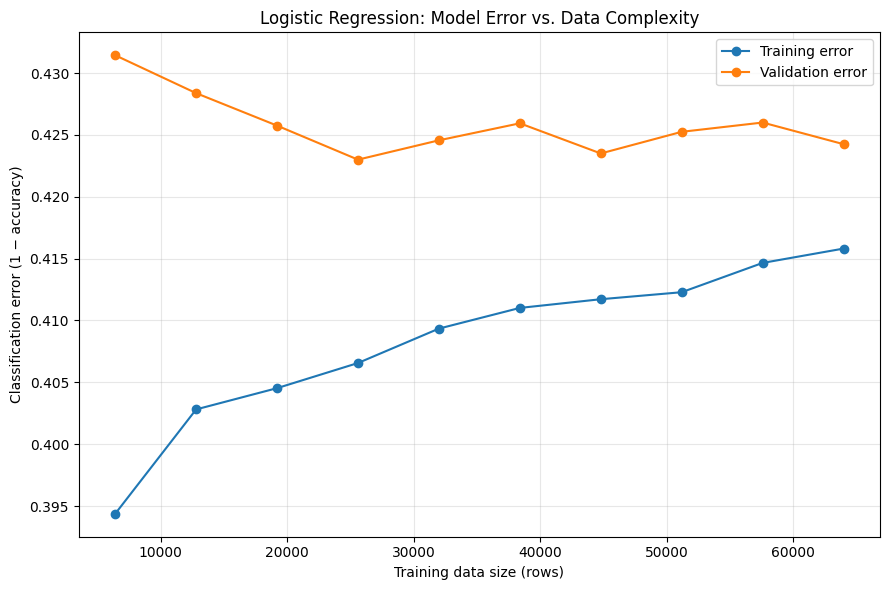

Saved chart to: /Users/augustenuunyango/logistic_regression_error_vs_data_complexity.png


In [5]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import zero_one_loss
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from model_utils import load_model_data, make_preprocessor, RANDOM_STATE

data_path = Path("/Users/augustenuunyango/data/cleaned_model_dataset.csv")
X_train, X_test, y_train, y_test = load_model_data(data_path)

# Set this to the folder where you want the chart saved.
output_dir = Path(".")
output_dir.mkdir(parents=True, exist_ok=True)

model = Pipeline([
    ("preprocessor", make_preprocessor(scale_numeric=True)),
    ("classifier", LogisticRegression(
        C=1.0,
        penalty="l2",
        solver="liblinear",
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE,)),])

# Hold out part of the training data for validation.
# Keep the test set untouched for final evaluation.
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_train,)

# Use increasing training-set sizes.
fractions = np.linspace(0.1, 1.0, 10)
sample_sizes = []
training_errors = []
validation_errors = []

for fraction in fractions:
    n = max(2, int(len(X_subtrain) * fraction))
    n = min(n, len(X_subtrain))

    # Use all rows directly on the final iteration; otherwise,
    # select a stratified subset.
    if n == len(X_subtrain):
        X_part, y_part = X_subtrain, y_subtrain
    else:
        X_part, _, y_part, _ = train_test_split(
            X_subtrain,
            y_subtrain,
            train_size=n,
            random_state=RANDOM_STATE,
            stratify=y_subtrain,
        )

    curve_model = clone(model)
    curve_model.fit(X_part, y_part)

    sample_sizes.append(len(X_part))
    training_errors.append(
        zero_one_loss(y_part, curve_model.predict(X_part))
    )
    validation_errors.append(
        zero_one_loss(y_val, curve_model.predict(X_val))
    )

plt.figure(figsize=(9, 6))
plt.plot(sample_sizes, training_errors, marker="o", label="Training error")
plt.plot(sample_sizes, validation_errors, marker="o", label="Validation error")
plt.xlabel("Training data size (rows)")
plt.ylabel("Classification error (1 − accuracy)")
plt.title("Logistic Regression: Model Error vs. Data Complexity")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

chart_path = output_dir / "logistic_regression_error_vs_data_complexity.png"
plt.savefig(chart_path, dpi=150)
plt.show()

print(f"Saved chart to: {chart_path.resolve()}")


**Searching for best model hyperparameters with GridSearchCV**

To get better results,  the model needs to be adjusted to handle regularization and class weights. Right now, class_weight="balanced" might actually be hurting the model's performance since the dataset is already fairly balanced (~10.8k zeros vs ~9.1k ones).


Instead of guessing the best numbers,I used GridSearchCV from Scikit-Learn. It will automatically test a grid of different hyperparameter combinations and pick the best tuning based on cleaned dataset.

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# 1. Setting up ML pipeline that links with preprocessed dataset and featured engineering dataset (Clean) 

model = Pipeline([
    ("preprocessor", make_preprocessor(scale_numeric=True)),
    ("classifier", LogisticRegression(
        solver="liblinear",  
        max_iter=2000,
        random_state=RANDOM_STATE))])

# 2. Setying up the grid of parameters to test

param_grid = {
    'classifier__C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0], 
    'classifier__penalty': ['l1', 'l2'],                     
    'classifier__class_weight': [None, 'balanced']}

# 3. Create the Grid Search object using ROC_AUC to maximise class separation

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,                      
    scoring='roc_auc',          
    n_jobs=-1)                  

# 4. Searching for best hypermarameters on training data

print("Searching for the best hyperparameters...")
grid_search.fit(X_train, y_train)


print("\nBest Hyperparameters found:")
print(grid_search.best_params_)

print(f"\nBest Cross-Validation ROC-AUC Score: {grid_search.best_score_:.4f}")

# 5. Extracting the final model (Logistical Regression)

best_model = grid_search.best_estimator_

**Results finding**

The grid search checked all options and selected C: 1.0, class_weight: 'balanced', and penalty: 'l2', which is the exact same parameters I started with. The cross-validation ROC-AUC score of 0.6062 is almost identical to your test ROC-AUC of 0.6088. This confirms that the Logistic Regression model cannot extract any more predictions from the features because it is a linear model trying to fit a non-linear, complex dataset.